La matrice di covarianza è simmetrica.
La matrice di covarianza ha elementi diagonali positivi.
La matrice di covarianza ha tutti autovalori positivi e quindi è definita positiva.
indice di correlazione tra alpha e delta: -0.650
La matrice di correlazione è simmetrica.
La matrice di correlazione ha elementi diagonali positivi.

--- Attività 2: Propagazione Lineare ---
a = 0.0364 ± 0.0007
d = 0.2072 ± 0.0019
q = 5.69 ± 0.15

--- Attività 3: Risultati Monte Carlo ---
a MC: Media = 0.0364, Std = 0.0007
d MC: Media = 0.2072, Std = 0.0019
q MC: Media = 5.69, Std = 0.15


<Figure size 800x600 with 0 Axes>

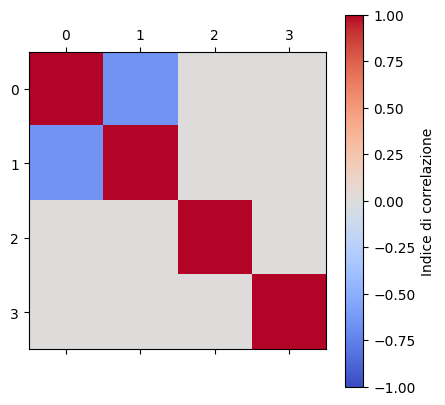

<Figure size 800x600 with 0 Axes>

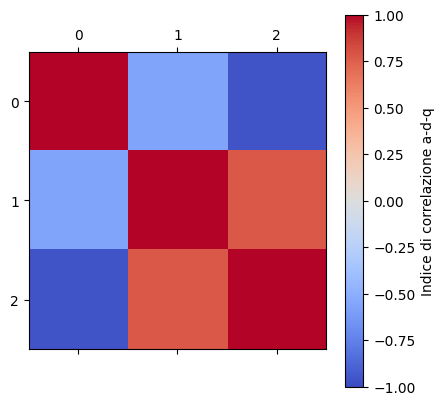

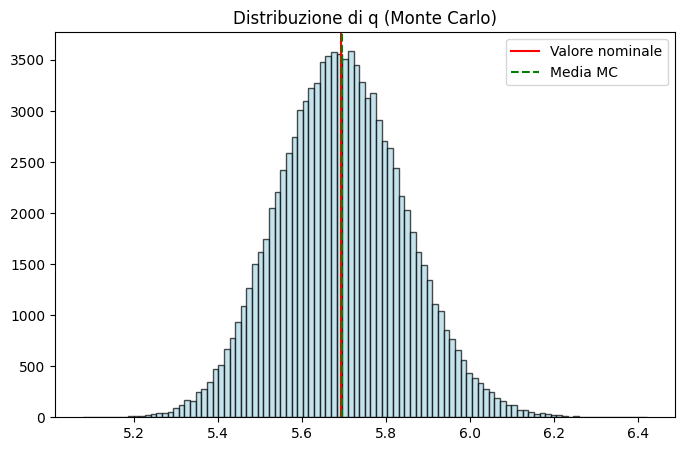

--- ATTIVITÀ 4: CONFRONTO CON CORRELAZIONE NULLA (rho_ad = 0) ---
u(a): nominale = 0.00073 | rho=0 (lin) = 0.00073 | rho=0 (MC) = 0.00073
u(d): nominale = 0.00189 | rho=0 (lin) = 0.00189 | rho=0 (MC) = 0.00189
u(q): nominale = 0.14954 | rho=0 (lin) = 0.12298 | rho=0 (MC) = 0.12273
--- ATTIVITÀ 5: CONTRIBUTI PERCENTUALI ALLA VARIANZA F_j(g) ---
Grandezza  |  Fit (alpha,delta) % |   Calibrazione k % | Calibrazione s_x %
--------------------------------------------------------------------------
a          |               98.00% |              1.00% |              1.00%
d          |               90.42% |              4.79% |              4.79%
q          |              100.00% |              0.00% |              0.00%


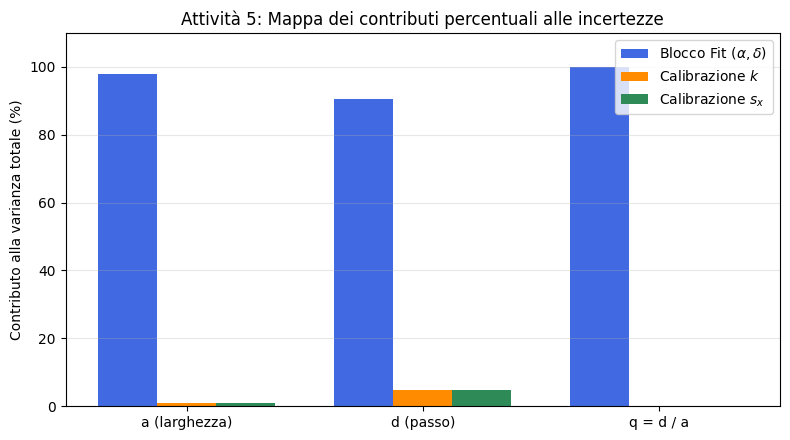

--- ATTIVITÀ 6: CONTROLLI DI STABILITÀ (SCENARI) ---
Scenario                         |   u(a) [mm] |   u(d) [mm] | u(q) [adim.]
---------------------------------------------------------------------------
1. Nominale                      |     0.00073 |     0.00189 |      0.14954
2. Correlazione ignorata (rho=0) |     0.00073 |     0.00189 |      0.12298
3. Calibrazione k dimezzata      |     0.00089 |     0.00346 |      0.14954
4. Calibrazione s_x dimezzata    |     0.00089 |     0.00346 |      0.14954
5. Statistica fit migliorata (/4) |     0.00037 |     0.00107 |      0.07477


In [32]:
import numpy as np
import matplotlib.pyplot as plt
#importo la libreria che mi permette di fare le derivate
import sympy as sp
x = sp.symbols('z[0], z[1], z[2], z[3]') 

#Parametri
k_hat=5.0
u_k=0.01
sx_hat=5.0
u_sx=0.01
alpha_hat=0.91
u_alpha=0.018
delta_hat=5.18
u_delta=0.045
rho_alpdel=-0.65
z=np.array(([alpha_hat, delta_hat, k_hat, sx_hat]))

#Costruzione della matrice di covarianza 
C_z=np.zeros((4,4))
C_z[0, 0]=u_alpha**2
C_z[1, 1]=u_delta**2
C_z[0, 1]=rho_alpdel*u_alpha*u_delta
C_z[1, 0]=C_z[0, 1]
#essendo k e sx indipendenti da alpha e delta, le covarianze sono nulle--> solo elementi sulla diagonale 
C_z[2, 2]=u_k**2
C_z[3, 3]=u_sx**2

#verifica simmetria
if np.allclose(C_z, C_z.T):
    print("La matrice di covarianza è simmetrica.")
#verifica diagonale positiva
if np.all(np.diag(C_z) > 0):
    print("La matrice di covarianza ha elementi diagonali positivi.")
#verifica definita positiva
eigenvalues = np.linalg.eigvals(C_z)
if np.all(eigenvalues > 0):
    print("La matrice di covarianza ha tutti autovalori positivi e quindi è definita positiva.")
else:
    print("La matrice di covarianza non  ha tutti autovalori positivi e quindi non è definita positiva.")

#Costruzione della matrice di corellazione
errori_z=np.sqrt(np.diag(C_z))
M_correlazione=C_z/np.outer(errori_z,errori_z)
print(f"indice di correlazione tra alpha e delta: {M_correlazione[0,1]}0")
plt.figure(figsize=(8, 6))
mappa=plt.matshow(M_correlazione, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(mappa, label='Indice di correlazione')

#verifica simmetria
if np.allclose(M_correlazione, M_correlazione.T):
    print("La matrice di correlazione è simmetrica.")
#verifica diagonale positiva
if np.all(np.diag(M_correlazione) > 0):
    print("La matrice di correlazione ha elementi diagonali positivi.")

#Progammazione analitica
#a = alpha/(k*sx)
#d = delta/(k*sx)
#q = d/a
#funzioni=np.array(([a, d, q])).T
#variabili=np.array(([alpha, delta, k, sx])).T     
#g_z = np.array(([a, d, q])).T                                                                       
#J = np.zeros((3, 4))
#calcolo delle derivate parziali della funzione g rispetto a z
#for i in range(3):
#    for j in range(4):
#        J[i, j] = sp.diff(sp.diff(g_z[j], x[i]), x[j])
#print(J)
#
#C_g = J @ C_z @ J.T
#diag_C_g = np.array(diag(C_g))

# Creiamo lo Jacobiano (matrice J) delle derivate parziali. 
J = np.zeros((3, 4))

# Derivate per 'a' = alpha / (k * sx)
J[0, 0] = 1 / (k_hat * sx_hat)
J[0, 2] = -alpha_hat / (k_hat**2 * sx_hat)
J[0, 3] = -alpha_hat / (k_hat * sx_hat**2)

# Derivate per 'd' = delta / (k * sx)
J[1, 1] = 1 / (k_hat * sx_hat)
J[1, 2] = -delta_hat / (k_hat**2 * sx_hat)
J[1, 3] = -delta_hat / (k_hat * sx_hat**2)

# Derivate per 'q'  = delta / alpha
J[2, 0] = -delta_hat / (alpha_hat**2)
J[2, 1] = 1 / alpha_hat

# Calcoliamo la propagazione lineare
C_g = J @ C_z @ J.T

u_a_lin = np.sqrt(C_g[0, 0])
u_d_lin = np.sqrt(C_g[1, 1])
u_q_lin = np.sqrt(C_g[2, 2])
u_g_lin =np.sqrt(np.diag(C_g))
#Stampa dei risultati di propagazione lineare
a_nom = alpha_hat / (k_hat * sx_hat)
d_nom = delta_hat / (k_hat * sx_hat)
q_nom = delta_hat / alpha_hat

print("\n--- Attività 2: Propagazione Lineare ---")
print(f"a = {a_nom:.4f} ± {u_a_lin:.4f}")
print(f"d = {d_nom:.4f} ± {u_d_lin:.4f}")
print(f"q = {q_nom:.2f} ± {u_q_lin:.2f}")


Corr_adq = np.zeros((3, 3))
for i in range(3):
    for j in range(3):
        Corr_adq[i, j] = C_g[i, j] / (np.sqrt(C_g[i, i]) * np.sqrt(C_g[j, j]))  
plt.figure(figsize=(8, 6))
mappa_adq=plt.matshow(Corr_adq, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(mappa_adq, label='Indice di correlazione a-d-q')

# ATTIVITÀ 3: Propagazione Monte Carlo
# Generiamo i campioni casuali.
rng = np.random.default_rng(20261003)
# multivariate_normal crea distribuzioni a campana tenendo conto delle correlazioni (C_z).
campioni = rng.multivariate_normal(mean=z, cov=C_z, size=100000)

# Estraiamo le colonne (0=alpha, 1=delta, 2=k, 3=sx)
alphas = campioni[:, 0]
deltas = campioni[:, 1]
ks = campioni[:, 2]
sxs = campioni[:, 3]

# Calcoliamo a, d, q per tutti i 100.000 
a_mc = alphas / (ks * sxs)
d_mc = deltas / (ks * sxs)
q_mc = deltas / alphas

print("\n--- Attività 3: Risultati Monte Carlo ---")
print(f"a MC: Media = {np.mean(a_mc):.4f}, Std = {np.std(a_mc, ddof=1):.4f}")
print(f"d MC: Media = {np.mean(d_mc):.4f}, Std = {np.std(d_mc, ddof=1):.4f}")
print(f"q MC: Media = {np.mean(q_mc):.2f}, Std = {np.std(q_mc, ddof=1):.2f}")

# Istogramma per q
plt.figure(figsize=(8,5))
plt.hist(q_mc, bins=100, color='lightblue', edgecolor='black', alpha=0.7)
plt.axvline(q_nom, color='red', label='Valore nominale')
plt.axvline(np.mean(q_mc), color='green', linestyle='--', label='Media MC')
plt.title("Distribuzione di q (Monte Carlo)")
plt.legend()
plt.show()

C_z_uncorr = C_z.copy()
C_z_uncorr[0, 1] = 0.0
C_z_uncorr[1, 0] = 0.0
C_g_uncorr = J @ C_z_uncorr @ J.T
u_g_uncorr = np.sqrt(np.diag(C_g_uncorr))
campioni_uncorr = rng.multivariate_normal(mean=z, cov=C_z_uncorr, size=100000)
a_mc_uncorr = campioni_uncorr[:, 0] / (campioni_uncorr[:, 2] * campioni_uncorr[:, 3])
d_mc_uncorr = campioni_uncorr[:, 1] / (campioni_uncorr[:, 2] * campioni_uncorr[:, 3])
q_mc_uncorr = campioni_uncorr[:, 1] / campioni_uncorr[:, 0]
std_mc_uncorr = np.array([np.std(a_mc_uncorr, ddof=1), np.std(d_mc_uncorr, ddof=1), np.std(q_mc_uncorr, ddof=1)])
print("--- ATTIVITÀ 4: CONFRONTO CON CORRELAZIONE NULLA (rho_ad = 0) ---")
print(f"u(a): nominale = {u_g_lin[0]:.5f} | rho=0 (lin) = {u_g_uncorr[0]:.5f} | rho=0 (MC) = {std_mc_uncorr[0]:.5f}")
print(f"u(d): nominale = {u_g_lin[1]:.5f} | rho=0 (lin) = {u_g_uncorr[1]:.5f} | rho=0 (MC) = {std_mc_uncorr[1]:.5f}")
print(f"u(q): nominale = {u_g_lin[2]:.5f} | rho=0 (lin) = {u_g_uncorr[2]:.5f} | rho=0 (MC) = {std_mc_uncorr[2]:.5f}")
#print(f"Variazione relativa su u(q) trascurando rho_ad: {100(u_g_uncorr[2] - u_g_lin[2])/u_g_lin[2]:+.1f}%")

#ATTIVITÀ 5: MAPPA DEI CONTRIBUTI (VARIANZE PARZIALI)
#Solo blocco fit (alpha, delta) attivo
C_fit_only = np.zeros((4, 4))
C_fit_only[:2, :2] = C_z[:2, :2]
var_fit = np.diag(J @ C_fit_only @ J.T)
#Solo calibrazione k attiva
C_k_only = np.zeros((4, 4))
C_k_only[2, 2] = u_k**2
var_k = np.diag(J @ C_k_only @ J.T)
#Solo calibrazione s_x attiva
C_sx_only = np.zeros((4, 4))
C_sx_only[3, 3] = u_sx**2
var_sx = np.diag(J @ C_sx_only @ J.T)
var_tot = var_fit + var_k + var_sx
F_fit = 100.0 * var_fit / var_tot
F_k = 100.0 * var_k / var_tot
F_sx = 100.0 * var_sx / var_tot
print("--- ATTIVITÀ 5: CONTRIBUTI PERCENTUALI ALLA VARIANZA F_j(g) ---")
print(f"{'Grandezza':<10} | {'Fit (alpha,delta) %':>20} | {'Calibrazione k %':>18} | {'Calibrazione s_x %':>18}")
print("-" * 74)
print(f"{'a':<10} | {F_fit[0]:19.2f}% | {F_k[0]:17.2f}% | {F_sx[0]:17.2f}%")
print(f"{'d':<10} | {F_fit[1]:19.2f}% | {F_k[1]:17.2f}% | {F_sx[1]:17.2f}%")
print(f"{'q':<10} | {F_fit[2]:19.2f}% | {F_k[2]:17.2f}% | {F_sx[2]:17.2f}%")

x_pos = np.arange(3)
larghezza = 0.25
plt.figure(figsize=(8, 4.5))
plt.bar(x_pos - larghezza, F_fit, width=larghezza, label=r'Blocco Fit $(\alpha, \delta)$', color='royalblue')
plt.bar(x_pos, F_k, width=larghezza, label=r'Calibrazione $k$', color='darkorange')
plt.bar(x_pos + larghezza, F_sx, width=larghezza, label=r'Calibrazione $s_x$', color='seagreen')
plt.xticks(x_pos, ['a (larghezza)', 'd (passo)', 'q = d / a'])
plt.ylabel("Contributo alla varianza totale (%)")
plt.ylim(0, 110)
plt.title("Attività 5: Mappa dei contributi percentuali alle incertezze")
plt.legend()
plt.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

#Controlli di stabilità

#Nominale
u_scen1 = u_g_lin
# Correlazione ignorata 
rho_ad = 0
u_scen2 = u_g_uncorr
#Scenario 3: Calibrazione k migliorata (u(k) dimezzata)
C_scen3 = C_z.copy()
C_scen3[2, 2] = (0.5 * u_k)
u_scen3 = np.sqrt(np.diag(J @ C_scen3 @ J.T))
#Scenario 4: Calibrazione s_x migliorata (u(s_x) dimezzata)
C_scen4 = C_z.copy()
C_scen4[3, 3] = (0.5 * u_sx)
u_scen4 = np.sqrt(np.diag(J @ C_scen4 @ J.T))
#Scenario 5: Statistica del fit migliorata (blocco C_ad diviso per 4)
C_scen5 = C_z.copy()
C_scen5[:2, :2] = C_z[:2, :2] / 4.0
u_scen5 = np.sqrt(np.diag(J @ C_scen5 @ J.T))
print("--- ATTIVITÀ 6: CONTROLLI DI STABILITÀ (SCENARI) ---")
print(f"{'Scenario':<32} | {'u(a) [mm]':>11} | {'u(d) [mm]':>11} | {'u(q) [adim.]':>12}")
print("-" * 75)
print(f"{'1. Nominale':<32} | {u_scen1[0]:11.5f} | {u_scen1[1]:11.5f} | {u_scen1[2]:12.5f}")
print(f"{'2. Correlazione ignorata (rho=0)':<32} | {u_scen2[0]:11.5f} | {u_scen2[1]:11.5f} | {u_scen2[2]:12.5f}")
print(f"{'3. Calibrazione k dimezzata':<32} | {u_scen3[0]:11.5f} | {u_scen3[1]:11.5f} | {u_scen3[2]:12.5f}")
print(f"{'4. Calibrazione s_x dimezzata':<32} | {u_scen4[0]:11.5f} | {u_scen4[1]:11.5f} | {u_scen4[2]:12.5f}")
print(f"{'5. Statistica fit migliorata (/4)':<32} | {u_scen5[0]:11.5f} | {u_scen5[1]:11.5f} | {u_scen5[2]:12.5f}")